# Modelagem Preditiva e Construção de Agentes de IA [26E4_3]

In [12]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, learning_curve, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

ARQUIVO_DADOS = "assinantes_neostream.csv"
COLUNA_ALVO = "churn"
COLUNAS_NUMERICAS = ["tempo_assinatura_meses", "uso_medio_semanal_horas", "numero_reclamacoes"]
COLUNAS_CATEGORICAS = ["plano", "metodo_pagamento", "dispositivo_principal"]
COLUNAS_LTV = ["tempo_assinatura_meses", "uso_medio_semanal_horas"]
TAMANHO_TESTE = 0.2
SEMENTE = 42
FOLDS_VALIDACAO = 5
VALORES_C = [0.01, 1, 100]
GRADE_HIPERPARAMETROS = {"classificador__C": [0.01, 0.1, 1, 10, 100]}
TAMANHO_AMOSTRA_GRAFICO = 1500

df = pd.read_csv(ARQUIVO_DADOS)


def dividir_estratificado(X, y):
    return train_test_split(X, y, test_size=TAMANHO_TESTE, stratify=y, random_state=SEMENTE)


def construir_preprocessador():
    return ColumnTransformer([
        ("numericas", StandardScaler(), COLUNAS_NUMERICAS),
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), COLUNAS_CATEGORICAS),
    ])


def construir_pipeline():
    return Pipeline([
        ("preprocessamento", construir_preprocessador()),
        ("classificador", LogisticRegression(max_iter=1000, random_state=SEMENTE)),
    ])


def buscar_melhor_c(pipeline, X_train, y_train):
    busca = GridSearchCV(
        pipeline,
        param_grid=GRADE_HIPERPARAMETROS,
        cv=FOLDS_VALIDACAO,
        scoring="roc_auc",
        n_jobs=-1,
    )
    return busca.fit(X_train, y_train)


def construir_modelo_svm(kernel, c):
    return Pipeline([
        ("padronizacao", StandardScaler()),
        ("svm", SVC(kernel=kernel, C=c)),
    ])


def plotar_fronteira(eixo, modelo, X, y, titulo, mostrar_vetores_suporte=False):
    DecisionBoundaryDisplay.from_estimator(
        modelo, X, response_method="predict", cmap="coolwarm", alpha=0.25, grid_resolution=300, ax=eixo
    )
    amostra = X.sample(TAMANHO_AMOSTRA_GRAFICO, random_state=SEMENTE)
    eixo.scatter(amostra.iloc[:, 0], amostra.iloc[:, 1], c=y.loc[amostra.index], cmap="coolwarm", s=8, alpha=0.5)
    if mostrar_vetores_suporte:
        vetores = modelo.named_steps["padronizacao"].inverse_transform(modelo.named_steps["svm"].support_vectors_)
        eixo.scatter(
            vetores[:, 0], vetores[:, 1],
            s=25, facecolors="none", edgecolors="black", linewidths=0.4, label="vetores de suporte",
        )
        eixo.legend(loc="upper right")
    eixo.set_xlabel(X.columns[0])
    eixo.set_ylabel(X.columns[1])
    eixo.set_title(titulo)

## Exercício 1

Verdadeiros negativos (VN): 1978
Falsos positivos (FP): 1
Falsos negativos (FN): 419
Verdadeiros positivos (VP): 2


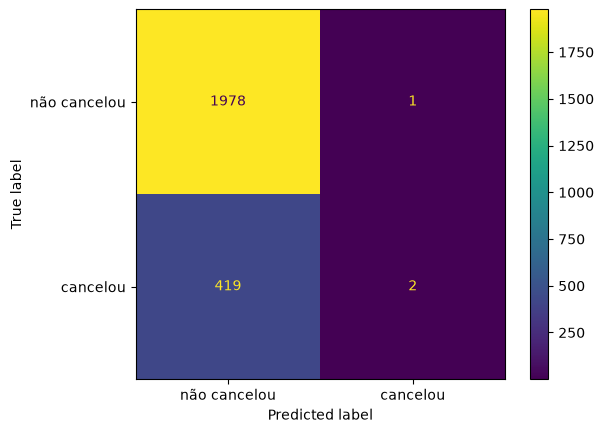

In [13]:
X_train, X_test, y_train, y_test = dividir_estratificado(
    df[COLUNAS_NUMERICAS + COLUNAS_CATEGORICAS], df[COLUNA_ALVO]
)
pipeline_tp1 = buscar_melhor_c(construir_pipeline(), X_train, y_train).best_estimator_

y_pred = pipeline_tp1.predict(X_test)
matriz = confusion_matrix(y_test, y_pred)
verdadeiros_negativos, falsos_positivos, falsos_negativos, verdadeiros_positivos = matriz.ravel()

print(f"Verdadeiros negativos (VN): {verdadeiros_negativos}")
print(f"Falsos positivos (FP): {falsos_positivos}")
print(f"Falsos negativos (FN): {falsos_negativos}")
print(f"Verdadeiros positivos (VP): {verdadeiros_positivos}")

ConfusionMatrixDisplay(matriz, display_labels=["não cancelou", "cancelou"]).plot();

### ANALISE DA MATRIZ DE CONFUSAO

| | Previsto: não cancela | Previsto: cancela |
|---|---|---|
| **Real: não cancelou** | VN = 1978 | FP = 1 |
| **Real: cancelou** | FN = 419 | VP = 2 |

- **VN (1978):** assinantes fiéis classificados como fiéis. Nenhuma ação é necessária e nenhum custo é gerado.
- **FP (1):** assinante fiel que receberia desconto sem precisar. O custo é o orçamento de campanha desperdiçado, e aqui é mínimo.
- **FN (419):** assinantes que cancelam sem nenhum alerta prévio. Cada um é receita recorrente perdida e uma chance de retenção desperdiçada, já que a equipe só descobre o cancelamento depois que ele acontece. Esse é o erro mais caro para o negócio, porque o custo de um desconto é menor que o de perder o assinante.
- **VP (2):** assinantes que cancelariam e foram alertados a tempo, o único caso em que a campanha de retenção tem chance de agir.

O modelo, com o limiar padrão de 0,5, dispara apenas 3 alertas em 2400 assinantes. Os alertas são confiáveis (2 de 3 corretos), mas a cobertura é desprezível: 419 de 421 cancelamentos (99,5%) passam despercebidos. Para a equipe de retenção, o modelo neste ponto de operação quase não detecta churn.

## Exercício 2

In [14]:
LIMIARES = [0.1, 0.2, 0.3, 0.5, 0.7]

probabilidades = pipeline_tp1.predict_proba(X_test)[:, 1]

linhas = []
for limiar in LIMIARES:
    y_pred_limiar = (probabilidades >= limiar).astype(int)
    linhas.append({
        "limiar": limiar,
        "alertas_disparados": y_pred_limiar.sum(),
        "precisao": precision_score(y_test, y_pred_limiar, zero_division=0),
        "recall": recall_score(y_test, y_pred_limiar),
    })

tradeoff = pd.DataFrame(linhas)
display(tradeoff.round(4))

,limiar,alertas_disparados,precisao,recall
0,0.1,2008,0.1977,0.9430
1,0.2,789,0.2636,0.4941
2,0.3,190,0.3579,0.1615
3,0.5,3,0.6667,0.0048
4,0.7,0,0.0000,0.0000


### TRADEOFF PRECISAO-RECALL

| Limiar | Alertas disparados | Precisão | Recall |
|---|---|---|---|
| 0,1 | 2008 | 0,1977 | 0,9430 |
| 0,2 | 789 | 0,2636 | 0,4941 |
| 0,3 | 190 | 0,3579 | 0,1615 |
| **0,5 (padrão)** | 3 | 0,6667 | 0,0048 |
| 0,7 | 0 | 0,0000 | 0,0000 |

- **Tendência:** quanto menor o limiar, mais assinantes são sinalizados. O recall sobe, mas a precisão cai, porque entram cada vez mais assinantes fiéis entre os alertas.
- **Limiar 0,7:** nenhum assinante atinge essa probabilidade (o máximo previsto é ~0,51), então não há alertas e a precisão é indefinida (tratada como 0).
- **Recomendação se a prioridade for não perder nenhum assinante em risco:** usar o menor limiar testado, **0,1**, que captura 94,3% dos cancelamentos reais. O custo é a precisão de 19,8% e 2008 alertas, ou seja, ~84% da base de teste receberia a campanha. Recall de 100% só existe com limiar próximo de 0, que alertaria todos os assinantes. Se o orçamento de campanha for limitado, o limiar 0,2 é um meio-termo (recall de 49,4% com 789 alertas), e a escolha final depende do custo do desconto frente ao valor do assinante retido.

## Exercício 3

AUC-ROC: 0.6640


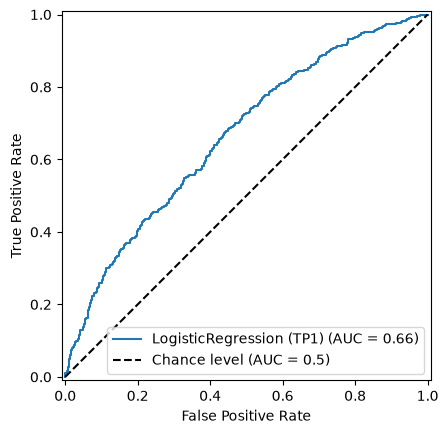

In [15]:
fpr, tpr, _ = roc_curve(y_test, probabilidades)
auc = roc_auc_score(y_test, probabilidades)

RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=auc, name="LogisticRegression (TP1)").plot(plot_chance_level=True)
print(f"AUC-ROC: {auc:.4f}")

### COMPARACAO AUC-ROC

O AUC-ROC do modelo é **0,6640**, contra 0,5 de um classificador aleatório.

AUC-ROC é adequada para comparar classificadores antes da escolha do limiar por quatro razões:
- **Independe do limiar:** a curva ROC varre todos os limiares possíveis e resume a taxa de verdadeiros positivos contra a de falsos positivos em um único número. Dois candidatos são comparados sem que o ponto de operação (ainda em negociação com o financeiro) já esteja fixado.
- **Mede a qualidade do ranking:** o AUC é a probabilidade de um assinante que cancelou receber score maior que um que não cancelou. Isso é o que importa quando o limiar vai ser escolhido depois.
- **Não depende da proporção de classes do mesmo modo que a acurácia:** com 18% de churn, prever "não cancela" para todos dá ~82% de acurácia e AUC de 0,5, e o AUC expõe que esse modelo não discrimina nada.
- **Permite a escolha posterior:** definido o melhor classificador pelo AUC, o limiar é escolhido depois, conforme o custo de falsos negativos e falsos positivos (Exercício 2).

## Exercício 4

In [16]:
def sigmoide(z):
    return 1 / (1 + np.exp(-z))


preprocessador = pipeline_tp1.named_steps["preprocessamento"]
classificador = pipeline_tp1.named_steps["classificador"]
coeficientes = classificador.coef_.ravel()
intercepto = classificador.intercept_[0]

display(pd.Series(coeficientes, index=preprocessador.get_feature_names_out(), name="coeficiente").round(4))
print(f"Intercepto: {intercepto:.4f}")

assinantes = X_test.iloc[:3]
combinacao_linear = preprocessador.transform(assinantes) @ coeficientes + intercepto

comparacao = pd.DataFrame({
    "combinacao_linear_z": combinacao_linear,
    "probabilidade_manual_sigmoide": sigmoide(combinacao_linear),
    "probabilidade_predict_proba": pipeline_tp1.predict_proba(assinantes)[:, 1],
}, index=assinantes.index)
display(comparacao.round(4))
print("Valores manuais idênticos ao predict_proba:", np.allclose(
    comparacao["probabilidade_manual_sigmoide"], comparacao["probabilidade_predict_proba"]
))

numericas__tempo_assinatura_meses               -0.4803
numericas__uso_medio_semanal_horas              -0.2034
numericas__numero_reclamacoes                    0.3110
categoricas__plano_basico                        0.0159
categoricas__plano_padrao                        0.0309
categoricas__plano_premium                      -0.0475
categoricas__metodo_pagamento_boleto             0.0215
categoricas__metodo_pagamento_cartao_credito    -0.0234
categoricas__metodo_pagamento_pix                0.0012
categoricas__dispositivo_principal_celular      -0.0182
categoricas__dispositivo_principal_computador    0.0364
categoricas__dispositivo_principal_smart_tv     -0.0155
categoricas__dispositivo_principal_tablet       -0.0035
Name: coeficiente, dtype: float64

Intercepto: -1.6503


,combinacao_linear_z,probabilidade_manual_sigmoide,probabilidade_predict_proba
5924,-1.5470,0.1755,0.1755
7890,-1.1546,0.2397,0.2397
1619,-0.7053,0.3306,0.3306


Valores manuais idênticos ao predict_proba: True


### DEMONSTRACAO SIGMOIDE

O modelo calcula, para cada assinante, a combinação linear das features já padronizadas e do one-hot, `z = b + w1·x1 + ... + w13·x13`, usando o intercepto `b` (-1,6503) e os coeficientes `w`. Como `z` pode assumir qualquer valor real, a função sigmoide `σ(z) = 1 / (1 + e^(-z))` o comprime para o intervalo (0, 1), que é lido como probabilidade de churn. `z = 0` corresponde a 50%, `z` negativo a menos de 50%, e `z` positivo a mais de 50%.

| Assinante (índice) | z | σ(z) manual | predict_proba |
|---|---|---|---|
| 5924 | -1,5470 | 0,1755 | 0,1755 |
| 7890 | -1,1546 | 0,2397 | 0,2397 |
| 1619 | -0,7053 | 0,3306 | 0,3306 |

Os valores manuais coincidem com `predict_proba` (a comparação `np.allclose` retorna `True`), confirmando que o `LogisticRegression` binário é exatamente a combinação linear seguida da sigmoide. Os três têm `z < 0`, portanto probabilidade menor que 0,5 e nenhum seria sinalizado com o limiar padrão. Os sinais dos coeficientes são coerentes: mais tempo de assinatura (-0,48) e mais uso (-0,20) reduzem o risco, e mais reclamações (+0,31) o aumentam.

## Exercício 5

In [17]:
X_plano_train, X_plano_test, y_plano_train, y_plano_test = dividir_estratificado(
    df[COLUNAS_NUMERICAS], df["plano"]
)

modelo_plano = Pipeline([
    ("padronizacao", StandardScaler()),
    ("classificador", LogisticRegression(max_iter=1000, random_state=SEMENTE)),
]).fit(X_plano_train, y_plano_train)

y_plano_pred = modelo_plano.predict(X_plano_test)
relatorio = pd.DataFrame(
    classification_report(y_plano_test, y_plano_pred, zero_division=0, output_dict=True)
).T
display(relatorio.round(2))

pior_classe = relatorio.loc[modelo_plano.classes_, "recall"].idxmin()
print(f"Classe com pior desempenho (menor acurácia por classe, ou seja, recall): {pior_classe}")

,precision,recall,f1-score,support
basico,0.41,0.86,0.55,972.00
padrao,0.41,0.15,0.22,937.00
premium,0.00,0.00,0.00,491.00
accuracy,0.41,0.41,0.41,0.41
macro avg,0.27,0.34,0.26,2400.00
weighted avg,0.32,0.41,0.31,2400.00


Classe com pior desempenho (menor acurácia por classe, ou seja, recall): premium


### REGRESSAO LOGISTICA MULTICLASSE

**Resultado:** a classe com pior desempenho é **premium**, com precisão, recall e f1 iguais a 0: o modelo nunca a prediz. A acurácia global (0,41) é praticamente a de prever sempre `basico` (0,405), que tem recall de 0,86, e `padrao` fica com recall de 0,15. Isso é esperado neste dataset: `plano` é sorteado de forma independente das demais colunas, então as features numéricas não carregam informação sobre ele, e o modelo recorre à classe mais frequente.

**Softmax:** na versão binária, a sigmoide transforma um único `z` em `P(y=1)`. Com K = 3 classes, o modelo mantém um vetor de pesos e um intercepto por classe, calcula uma pontuação `z_k = w_k · x + b_k` para cada uma e as transforma em probabilidades com a softmax:

`P(classe k) = e^(z_k) / (e^(z_1) + e^(z_2) + e^(z_3))`

As três probabilidades ficam entre 0 e 1 e somam 1, e a classe prevista é a de maior probabilidade. A sigmoide é o caso particular de duas classes: a softmax entre `z_1` e `z_0` equivale a `σ(z_1 - z_0)`. O treino minimiza a entropia cruzada, a generalização da log-loss binária.

## Exercício 6

,C,roc_auc_treino,roc_auc_validacao,gap
0,0.01,0.6613,0.6578,0.0035
1,1.00,0.6615,0.6574,0.0041
2,100.00,0.6615,0.6574,0.0041


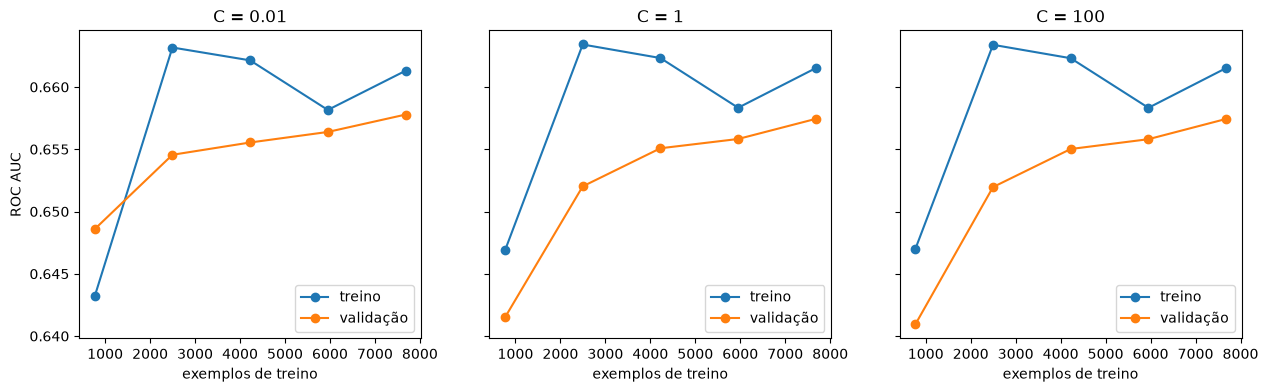

In [18]:
TAMANHOS_RELATIVOS = np.linspace(0.1, 1.0, 5)

fig, eixos = plt.subplots(1, len(VALORES_C), figsize=(15, 4), sharey=True)
resumo = []
for eixo, c in zip(eixos, VALORES_C):
    tamanhos, scores_treino, scores_validacao = learning_curve(
        construir_pipeline().set_params(classificador__C=c),
        X_train,
        y_train,
        train_sizes=TAMANHOS_RELATIVOS,
        cv=FOLDS_VALIDACAO,
        scoring="roc_auc",
        n_jobs=-1,
    )
    media_treino = scores_treino.mean(axis=1)
    media_validacao = scores_validacao.mean(axis=1)

    eixo.plot(tamanhos, media_treino, marker="o", label="treino")
    eixo.plot(tamanhos, media_validacao, marker="o", label="validação")
    eixo.set_title(f"C = {c}")
    eixo.set_xlabel("exemplos de treino")
    eixo.legend()

    resumo.append({
        "C": c,
        "roc_auc_treino": media_treino[-1],
        "roc_auc_validacao": media_validacao[-1],
        "gap": media_treino[-1] - media_validacao[-1],
    })

eixos[0].set_ylabel("ROC AUC")
display(pd.DataFrame(resumo).round(4))

### ANALISE DA REGULARIZACAO RIDGE

As curvas usam ROC AUC (como no TP1), porque a acurácia é dominada pela classe majoritária. Resultados com todo o treino disponível:

| C | ROC AUC treino | ROC AUC validação | Gap |
|---|---|---|---|
| 0,01 | 0,6613 | 0,6578 | 0,0035 |
| 1 | 0,6615 | 0,6574 | 0,0041 |
| 100 | 0,6615 | 0,6574 | 0,0041 |

**Recomendação: C = 0,01.** É o valor com o menor gap entre treino e validação e com a melhor validação, sem perda de desempenho em relação aos demais, e coincide com o melhor `C` do GridSearchCV do TP1.

**Sobre a suspeita de overfitting:** os dados não a confirmam. O gap é menor que 0,005 de AUC em todos os casos, e o eixo vertical dos gráficos cobre apenas ~0,025, o que visualmente amplifica diferenças pequenas. A curva de validação ainda sobe levemente com mais dados e as de `C = 1` e `C = 100` são praticamente idênticas, ou seja, a regularização quase não altera o modelo. O limite do desempenho (AUC ~0,66) vem do sinal fraco nas features, e mais dados ou outro `C` não devem mudar isso de forma relevante.

## Exercício 7

Vetores de suporte: 3031 de 9600 exemplos de treino
Acurácia no teste: 0.8562
Acurácia de prever sempre a classe majoritária: 0.8379


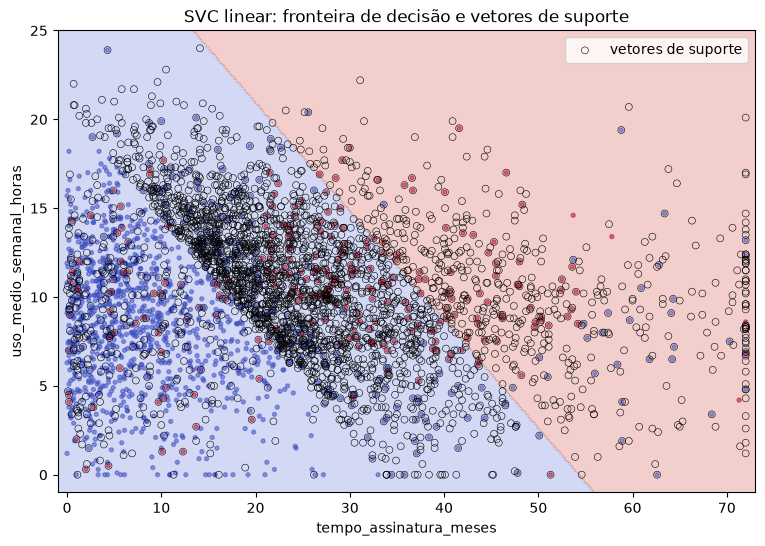

In [19]:
X_ltv_train, X_ltv_test, y_ltv_train, y_ltv_test = dividir_estratificado(df[COLUNAS_LTV], df["ltv_alto"])

modelo_linear = construir_modelo_svm("linear", c=1).fit(X_ltv_train, y_ltv_train)

fig, eixo = plt.subplots(figsize=(9, 6))
plotar_fronteira(
    eixo, modelo_linear, X_ltv_train, y_ltv_train,
    "SVC linear: fronteira de decisão e vetores de suporte", mostrar_vetores_suporte=True,
)

n_vetores = modelo_linear.named_steps["svm"].n_support_.sum()
print(f"Vetores de suporte: {n_vetores} de {len(X_ltv_train)} exemplos de treino")
print(f"Acurácia no teste: {modelo_linear.score(X_ltv_test, y_ltv_test):.4f}")
print(f"Acurácia de prever sempre a classe majoritária: {1 - y_ltv_test.mean():.4f}")

### SVM MARGEM MAXIMA

Usei `tempo_assinatura_meses` e `uso_medio_semanal_horas`, o par de features em que o `ltv_alto` é definido (conforme o script de geração do dataset).

O SVM linear busca o hiperplano que separa as classes com a **maior margem** possível, isto é, a maior distância até os exemplos mais próximos de cada classe. Os **vetores de suporte** são os exemplos que ficam sobre a margem ou dentro dela (ou do lado errado dela, quando as classes se sobrepõem). Só eles determinam a posição da fronteira: removendo qualquer outro exemplo, o hiperplano não muda. Na `LogisticRegression` é diferente: a fronteira vem da minimização da log-loss sobre **todos** os exemplos, e cada um contribui para os coeficientes (os mais distantes da fronteira com peso pequeno, mas contribuem).

**Observação sobre o gráfico:** neste dataset as classes se sobrepõem, então 3032 dos 9600 exemplos de treino viraram vetores de suporte, e a fronteira reta acompanha mal a região de alto valor: a acurácia de 0,8562 fica pouco acima da de prever sempre a classe majoritária (0,8379). É uma primeira versão, e o Exercício 9 testa uma fronteira curva.

## Exercício 8

In [20]:
resultados = []
for c in VALORES_C:
    modelo = construir_modelo_svm("linear", c).fit(X_ltv_train, y_ltv_train)
    resultados.append({
        "C": c,
        "vetores_de_suporte": modelo.named_steps["svm"].n_support_.sum(),
        "acuracia_treino": modelo.score(X_ltv_train, y_ltv_train),
        "acuracia_teste": modelo.score(X_ltv_test, y_ltv_test),
    })

resultados = pd.DataFrame(resultados)
display(resultados.round(4))

,C,vetores_de_suporte,acuracia_treino,acuracia_teste
0,0.01,3077,0.8500,0.8492
1,1.00,3031,0.8567,0.8562
2,100.00,3033,0.8567,0.8562


### AJUSTE SOFT MARGIN

| C | Vetores de suporte | Acurácia treino | Acurácia teste |
|---|---|---|---|
| 0,01 | 3077 | 0,8500 | 0,8492 |
| 1 | 3031 | 0,8567 | 0,8562 |
| 100 | 3033 | 0,8567 | 0,8562 |

`C` controla o quanto o modelo tolera exemplos dentro da margem ou do lado errado: `C` pequeno dá margem larga e tolerante (mais regularização, mais bias), `C` grande penaliza fortemente os erros e deixa a margem estreita (menos bias, mais variância).

**Melhor equilíbrio: C = 1.**
- **C = 0,01** é permissivo demais: a acurácia cai tanto no treino (0,8500) quanto no teste (0,8492), o que indica underfitting, e usa mais vetores de suporte.
- **C = 100** não traz ganho algum em relação a `C = 1` (mesma acurácia no treino e no teste), apenas deixa a margem mais rígida e o treino muito mais lento.
- **C = 1** atinge o melhor resultado com a regularização mais forte entre os empatados, o que protege contra variância.

Em todos os casos o gap treino-teste é de ~0,0005, ou seja, a variância é baixa e o limite vem do **bias do modelo linear**: a acurácia fica em ~0,856 independentemente de `C`, porque a região de alto valor é curva. Ajustar `C` não resolve isso, e o próximo passo é mudar o kernel (Exercício 9).

## Exercício 9

Kernel linear (C=1.0): acurácia no teste = 0.8562
Kernel rbf (C=1.0): acurácia no teste = 0.9471


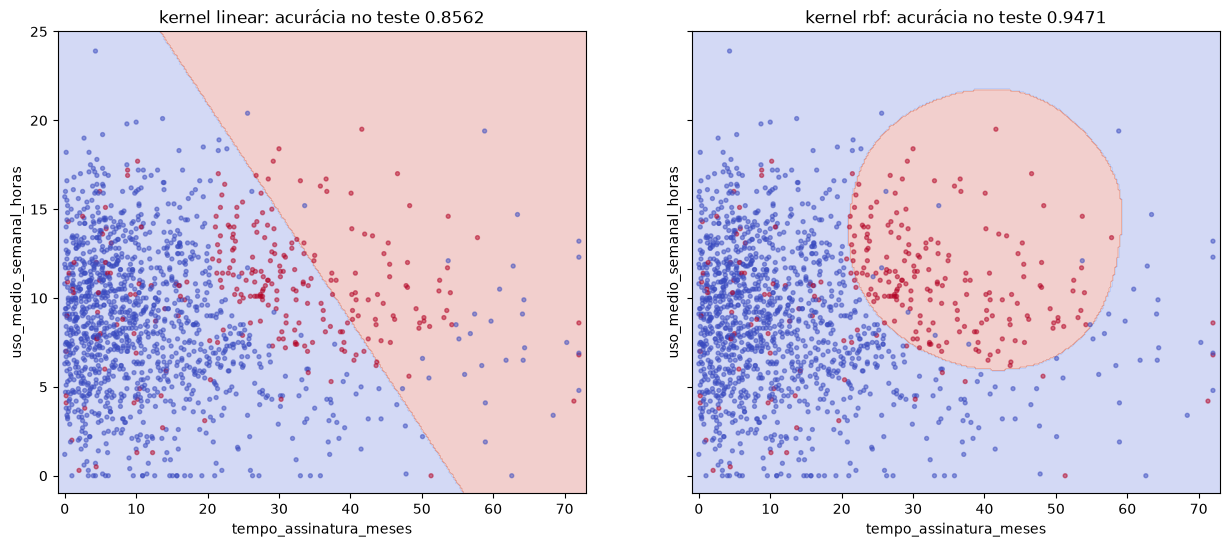

In [21]:
melhor_c = resultados.sort_values(["acuracia_teste", "C"], ascending=[False, True]).iloc[0]["C"]

fig, eixos = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
for eixo, kernel in zip(eixos, ["linear", "rbf"]):
    modelo = construir_modelo_svm(kernel, melhor_c).fit(X_ltv_train, y_ltv_train)
    acuracia = modelo.score(X_ltv_test, y_ltv_test)
    print(f"Kernel {kernel} (C={melhor_c}): acurácia no teste = {acuracia:.4f}")
    plotar_fronteira(eixo, modelo, X_ltv_train, y_ltv_train, f"kernel {kernel}: acurácia no teste {acuracia:.4f}")

### KERNEL RBF

| Kernel | Acurácia no teste |
|---|---|
| Linear (C = 1) | 0,8562 |
| RBF (C = 1) | 0,9471 |

O RBF ganha ~9 pontos percentuais, e o gráfico mostra o motivo: a fronteira linear corta o plano com uma reta, enquanto a do RBF forma uma região fechada e curva, que acompanha a região de assinantes de alto valor.

O SVM só precisa dos **produtos internos** entre os exemplos, nunca das coordenadas num espaço maior. O kernel RBF, `K(x, x') = exp(-γ · ||x - x'||²)`, calcula diretamente o resultado de um produto interno em um espaço de dimensão infinita, sem que as features sejam mapeadas para ele (o "kernel trick"). A decisão para um novo ponto é uma soma ponderada de `K(x, vetor_de_suporte)`, ou seja, de "colinas" centradas nos vetores de suporte, cuja largura é controlada por `γ`. A soma dessas colinas produz uma fronteira curva sem que seja necessário criar manualmente novas combinações polinomiais das features.

## Exercício 10

Melhor C do SVC (RBF): 100
Melhor ROC AUC em validação cruzada: 0.5669


,modelo,VN,FP,FN,VP,precisao,recall,auc_roc
0,LogisticRegression,1978,1,419,2,0.6667,0.0048,0.6640
1,SVC (RBF),1944,35,401,20,0.3636,0.0475,0.5559


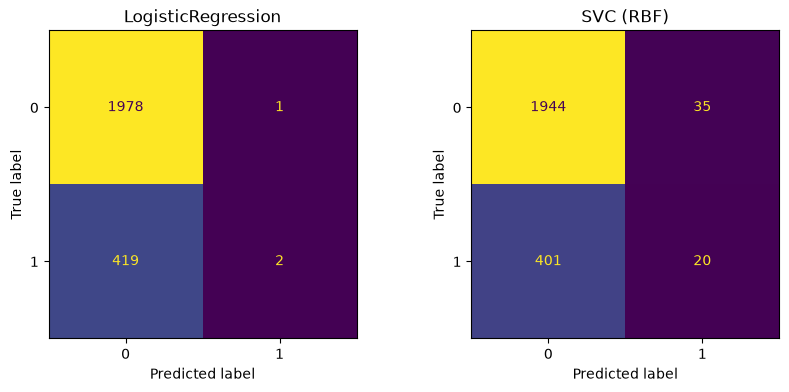

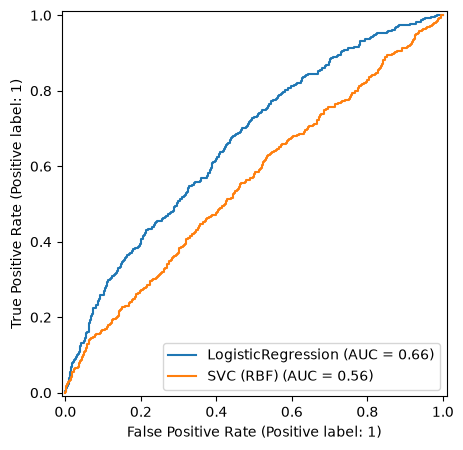

In [22]:
pipeline_svc = Pipeline([
    ("preprocessamento", construir_preprocessador()),
    ("classificador", SVC(kernel="rbf")),
])
busca_svc = buscar_melhor_c(pipeline_svc, X_train, y_train)
print(f"Melhor C do SVC (RBF): {busca_svc.best_params_['classificador__C']}")
print(f"Melhor ROC AUC em validação cruzada: {busca_svc.best_score_:.4f}")

modelos = {"LogisticRegression": pipeline_tp1, "SVC (RBF)": busca_svc.best_estimator_}

fig_matrizes, eixos_matrizes = plt.subplots(1, 2, figsize=(10, 4))
fig_roc, eixo_roc = plt.subplots(figsize=(6, 5))
metricas = []
for eixo, (nome, modelo) in zip(eixos_matrizes, modelos.items()):
    y_pred_modelo = modelo.predict(X_test)
    scores = modelo.decision_function(X_test)

    ConfusionMatrixDisplay.from_predictions(y_test, y_pred_modelo, ax=eixo, colorbar=False)
    eixo.set_title(nome)
    RocCurveDisplay.from_predictions(y_test, scores, name=nome, ax=eixo_roc)

    vn, fp, fn, vp = confusion_matrix(y_test, y_pred_modelo).ravel()
    metricas.append({
        "modelo": nome,
        "VN": vn,
        "FP": fp,
        "FN": fn,
        "VP": vp,
        "precisao": precision_score(y_test, y_pred_modelo, zero_division=0),
        "recall": recall_score(y_test, y_pred_modelo),
        "auc_roc": roc_auc_score(y_test, scores),
    })

display(pd.DataFrame(metricas).round(4))

### DECISAO MODELO CHURN

| Modelo | VN | FP | FN | VP | Precisão | Recall | AUC-ROC |
|---|---|---|---|---|---|---|---|
| LogisticRegression | 1978 | 1 | 419 | 2 | 0,6667 | 0,0048 | **0,6640** |
| SVC (RBF), C = 100 | 1944 | 35 | 401 | 20 | 0,3636 | 0,0475 | 0,5559 |

**Recomendação: levar a LogisticRegression para produção.**

- **Discriminação (AUC-ROC):** a regressão logística tem 0,6640 contra 0,5559 do SVC, que fica perto do classificador aleatório (0,5). Como o AUC independe do limiar, é a comparação mais justa entre os dois, e a diferença é grande. O melhor `C` do SVC (100) está no limite superior da grade e mesmo assim o desempenho fica bem abaixo.
- **Falsos negativos (custo discutido no Exercício 1):** no limiar padrão, o SVC deixa passar 401 cancelamentos contra 419 da regressão, uma diferença pequena, e à custa de 35 falsos positivos contra 1. Em ambos os casos o recall é desprezível (4,8% e 0,5%), e o ponto de operação padrão não serve para nenhum dos dois. O que decide a escolha é então a qualidade do ranking, porque o limiar será ajustado depois.
- **Controle do limiar:** como o Exercício 2 mostrou, baixar o limiar da regressão para 0,1 leva o recall a 94,3%, com custo de precisão (19,8%). Isso permite à equipe de retenção escolher o ponto conforme o orçamento. O SVC não fornece probabilidades calibradas por padrão, e seu ranking é pior.
- **Custo operacional:** a regressão é interpretável (Exercício 4: tempo de assinatura e uso reduzem o risco, reclamações o aumentam), treina em frações de segundo e é mais simples de manter.

**Ressalva:** o desempenho de ambos é modesto (AUC máximo 0,66), porque o sinal nas features é fraco. Antes de acionar campanhas, o limiar da regressão precisa ser definido com o time de produto e o financeiro.